In [1]:
import xarray as xr
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr 

In [2]:
def get_out_dir(latmin, latmax, lonmin, lonmax):
    if latmin < 0:
        strlatmin = str(latmin*-1) + 'S'
    else:
        strlatmin = str(latmin) + 'N'
    if latmax < 0:
        strlatmax = str(latmax*-1) + 'S'
    else:
        strlatmax = str(latmax) + 'N'
    if lonmin < 0:
        strlonmin = str(lonmin*-1) + 'W'
    else:
        strlonmin = str(lonmin) + 'E'
    if lonmax < 0:
        strlonmax = str(lonmax*-1) + 'W'
    else:
        strlonmax = str(lonmax) + 'E'
        
    return(strlatmin + '-' + strlatmax + '_' + strlonmin + '-' + strlonmax)

2020
2020 * calc time:23.48 seconds


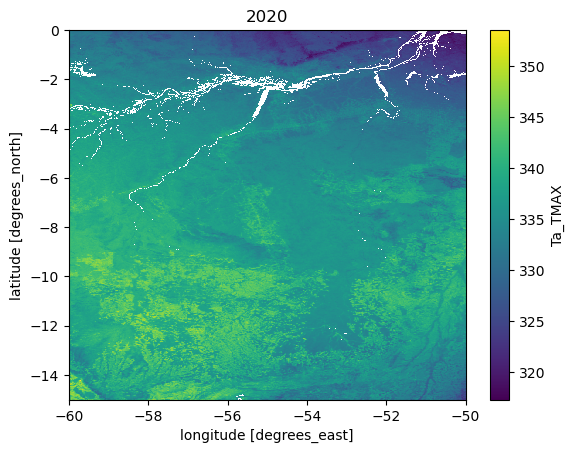

In [3]:
# read in and plot air T data for 2020
# 1 km Air temperature data from Zhang and Zhou here: https://iastate.figshare.com/collections/A_global_1_km_resolution_daily_near-surface_air_temperature_dataset_2003_2020_/6005185
# methods from here: https://www.nature.com/articles/s41467-020-16970-7
year = 2020
print(year)
start_time = time.time()
data_path = '/scratch/earjba/'  # data copied to viper scratch space
fname = 'SouthAmerica_Ta_SVCMsp_' + str(year) + 'TMAX_daily_tropics30N30S.nc'
chunks = {"lat": 'auto', 'lon':'auto', 'DOY':-1}
ds_2020 = xr.open_dataset(data_path + fname,
                          chunks=chunks)
ds_2020

geo_lims = {'lat':slice(0, -15),
            'lon':slice(-60, -50)}

tmax_2020 = ds_2020.Ta_TMAX.sel(**geo_lims)
tmax_2020.shape
plt.figure()
tmax_2020.mean(axis=0).plot()
plt.title(year)
out_path = '/nfs/see-fs-02_users/earjba/public_html/plots/python_plots/'
plt.savefig(out_path+'zhang_zhou_' + str(year) + 'Tmax_amazon.png', dpi=300, bbox_inches='tight') 

end_time = time.time()
execution_time = end_time - start_time
print(year, "* calc time:{0:0.02f} seconds".format(execution_time))


[-4.68958206e-12 -1.00000000e-02 -2.00000000e-02 -3.00000000e-02
 -4.00000000e-02 -5.00000000e-02 -6.00000000e-02 -7.00000000e-02
 -8.00000000e-02 -9.00000000e-02]


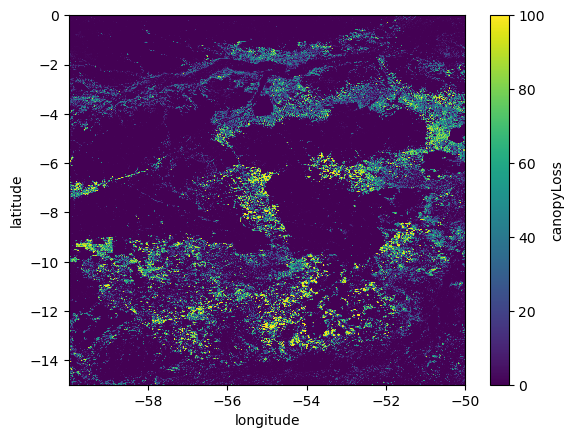

In [4]:
# read in canopy loss data  
data_path = '/scratch/earjba/' 
fname = 'canopyLoss_2003-2020_hansen-v1.8_0.01deg_pantropical.nc'
ds = xr.open_dataset(data_path+fname, engine='netcdf4')
canopyLoss = ds.canopyLoss

geo_lims = {'latitude':slice(-15, 0),
            'longitude':slice(-60, -50)}

canopyLoss = canopyLoss.sel(**geo_lims)

canopyLoss = canopyLoss.reindex(latitude=canopyLoss.latitude[::-1])  #flip lats - might need to comment out

print(canopyLoss.latitude.values[0:10])

#print(canopyLoss.shape)
canopyLoss.plot()

In [5]:
temp_list_percentiles = {}

In [8]:
#assert False
# read in and plot percentile data - need to concat by DOY because separate file for each day of year
# stitch together from latlon tiles
# need to get list of filenames then read in together
fnames_percentiles = []
# create dictionary to store data for each 5 x 5 section

for lon in range(-70, -40, +5):
    for lat in range(-20, 0, 5):
        latmin, latmax = lat, lat + 5
        lonmin, lonmax = lon, lon + 5

        datadir = get_out_dir(latmin, latmax, lonmin, lonmax)
        print(datadir)

        data_path = '/nfs/b0122/earjba/heatwaves/zhang_and_zhou_percentiles/' + datadir + '/'
        fpaths = glob.glob(data_path + '*.nc')
        #print(fpaths)
        fnames_percentiles += fpaths
        chunks = 'auto'
        
        ds = xr.open_mfdataset(fpaths[0:], engine='netcdf4', 
                               combine='nested', concat_dim='DOY',
                               chunks=chunks, parallel=True)
        #print(ds.ZZ_AirT_95_percentile.shape)
        temp_list_percentiles[datadir] = ds
        #print(np.nanmean(ds.ZZ_AirT_95_percentile.mean(dim=['longitude', 'latitude']).values)*0.1)
        #print(np.nanmean(ds.ZZ_AirT_95_percentile.values[200, :, :])*0.1)

20S-15S_70W-65W
15S-10S_70W-65W
10S-5S_70W-65W
5S-0N_70W-65W
20S-15S_65W-60W
15S-10S_65W-60W
10S-5S_65W-60W
5S-0N_65W-60W
20S-15S_60W-55W
15S-10S_60W-55W
10S-5S_60W-55W
5S-0N_60W-55W
20S-15S_55W-50W
15S-10S_55W-50W
10S-5S_55W-50W
5S-0N_55W-50W
20S-15S_50W-45W
15S-10S_50W-45W
10S-5S_50W-45W
5S-0N_50W-45W
20S-15S_45W-40W
15S-10S_45W-40W
10S-5S_45W-40W
5S-0N_45W-40W


In [9]:
# concatenate in latitudes direction first

# # 70W-65W
ds_70lon = xr.concat([
                      temp_list_percentiles['5S-0N_70W-65W'],
                      temp_list_percentiles['10S-5S_70W-65W'],
                      temp_list_percentiles['15S-10S_70W-65W'],
                      temp_list_percentiles['20S-15S_70W-65W']  
                      ], dim='latitude')
print(ds_70lon.ZZ_AirT_95_percentile.shape)

# # 65W-60W
ds_65lon = xr.concat([
                      temp_list_percentiles['5S-0N_65W-60W'],
                      temp_list_percentiles['10S-5S_65W-60W'],
                      temp_list_percentiles['15S-10S_65W-60W'],
                      temp_list_percentiles['20S-15S_65W-60W']  
                      ], dim='latitude')
print(ds_65lon.ZZ_AirT_95_percentile.shape)

# # 60W-55W
ds_60lon = xr.concat([
                      temp_list_percentiles['5S-0N_60W-55W'],
                      temp_list_percentiles['10S-5S_60W-55W'],
                      temp_list_percentiles['15S-10S_60W-55W'],
                      temp_list_percentiles['20S-15S_60W-55W']  
                      ], dim='latitude')
print(ds_60lon.ZZ_AirT_95_percentile.shape)

# 55W-50W
ds_55lon = xr.concat([temp_list_percentiles['5S-0N_55W-50W'],
                      temp_list_percentiles['10S-5S_55W-50W'],
                      temp_list_percentiles['15S-10S_55W-50W'],
                      temp_list_percentiles['20S-15S_55W-50W']  
                      ], dim='latitude')
print(ds_55lon.ZZ_AirT_95_percentile.shape)

# 50W-45W
ds_50lon = xr.concat([temp_list_percentiles['5S-0N_50W-45W'],
                      temp_list_percentiles['10S-5S_50W-45W'],
                      temp_list_percentiles['15S-10S_50W-45W'],
                      temp_list_percentiles['20S-15S_50W-45W']  
                      ], dim='latitude')
print(ds_50lon.ZZ_AirT_95_percentile.shape)

# 45W-40W
ds_45lon = xr.concat([temp_list_percentiles['5S-0N_45W-40W'],
                      temp_list_percentiles['10S-5S_45W-40W'],
                      temp_list_percentiles['15S-10S_45W-40W'],
                      temp_list_percentiles['20S-15S_45W-40W']  
                      ], dim='latitude')
print(ds_45lon.ZZ_AirT_95_percentile.shape)

(365, 2613, 653)
(365, 2613, 653)
(365, 2613, 654)
(365, 2613, 653)
(365, 2613, 653)
(365, 2613, 654)


In [10]:
# concatenate in longitude direction
full_ds = xr.concat([ds_60lon, ds_55lon, ds_50lon], dim='longitude')
print(full_ds.ZZ_AirT_95_percentile.shape)

(365, 2613, 1960)


41.155


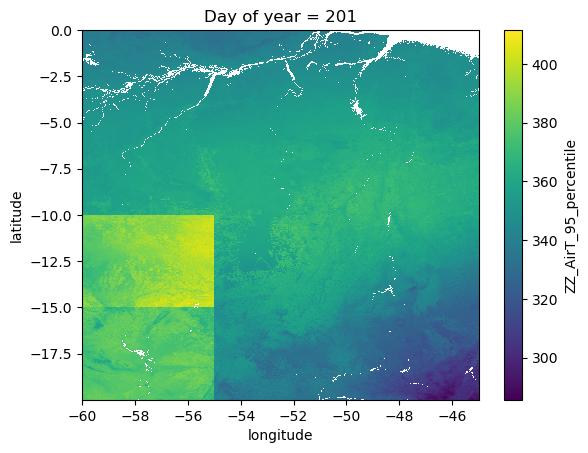

In [13]:
# plot percentile data for individual days of year
doy = 200
full_ds.ZZ_AirT_95_percentile[doy, :, :].plot()
print(np.nanmax(full_ds.ZZ_AirT_95_percentile[doy, :, :].values)*0.1)
#plt.imshow(full_ds.ZZ_AirT_95_percentile[doy, :, :].values, origin='lower')
plt.title('Day of year = ' + str(doy+1))
out_path = '/nfs/see-fs-02_users/earjba/public_html/plots/python_plots/'
plt.savefig(out_path+'zhang_zhou_percentile_map_amazon_DOY' + str(doy+1) + '.png', dpi=300, bbox_inches='tight') 

In [ ]:
# line plot of percentile values (degrees C) for single point
plt.plot(range(0,365), ds.ZZ_AirT_95_percentile.values[:, 0, 0]*0.1)

In [ ]:
# line plot of percentile values (degrees C) for spatial average
plt.plot(range(0,365), ds.ZZ_AirT_95_percentile.mean(dim=['longitude', 'latitude']).values*0.1)

In [ ]:
# line plot of percentile values (degrees C) for single point
plt.plot(range(0,365), ds.ZZ_AirT_95_percentile.mean(dim=['longitude', 'latitude']).values*0.1)

In [ ]:
# line plot of percentile values (degrees C) for spatial average
plt.plot(range(0,365), tmax_2020.mean(dim=['lon', 'lat']).values*0.1)